In [ ]:
!pip install -q kagglehub tensorflow_hub transformers torch

import kagglehub
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import train_test_split
import os
import time
import pickle
import pandas as pd

In [ ]:
path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
DATA_DIR = os.path.join(path, "Garbage classification", "Garbage classification")
class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
NUM_CLASSES = 6
IMG_SIZE = 224

# Load file paths
file_paths = []
labels = []
for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    for img_file in os.listdir(class_dir):
        if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
            file_paths.append(os.path.join(class_name, img_file))
            labels.append(class_idx)

# 80/20 split
train_paths, test_paths, train_labels, test_labels = train_test_split(
    file_paths, labels, test_size=0.2, stratify=labels, random_state=42
)

# 90/10 train/val split (from 80% pool)
train_paths_final, val_paths_final, train_labels_final, val_labels_final = train_test_split(
    train_paths, train_labels, test_size=0.1, stratify=train_labels, random_state=42
)

print(f"Train: {len(train_paths_final)}, Val: {len(val_paths_final)}, Test: {len(test_paths)}")

Using Colab cache for faster access to the 'garbage-classification' dataset.
Train: 1818, Val: 203, Test: 506


In [ ]:
def preprocess_image(image_path, label):
    full_path = tf.strings.join([DATA_DIR, "/", image_path])
    image = tf.io.read_file(full_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augment_cnn(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    return image, label

def create_dataset(paths, labels, batch_size, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(augment_cnn, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(lambda x, y: (x, tf.cast(y, tf.int32)))
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

# Create datasets
BATCH_SIZE = 16
train_ds = create_dataset(train_paths_final, train_labels_final, BATCH_SIZE, augment=True)
val_ds = create_dataset(val_paths_final, val_labels_final, BATCH_SIZE, augment=False)

In [ ]:
from transformers import ViTModel
import torch

print("Loading pretrained weights from HuggingFace...")
pt_model = ViTModel.from_pretrained('google/vit-base-patch16-224')
pt_model.eval()
pt_weights = {name: param.detach().numpy() for name, param in pt_model.named_parameters()}
print(f"Loaded {len(pt_weights)} weight tensors")

def mlp_block(x, hidden_dim, out_dim, name):
    x = keras.layers.Dense(hidden_dim, activation='gelu', name=f"{name}_fc1")(x)
    x = keras.layers.Dense(out_dim, name=f"{name}_fc2")(x)
    return x

def attention_block(x, num_heads, head_dim, embed_dim, name):
    q = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_q")(x)
    k = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_k")(x)
    v = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_v")(x)

    q = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_q_reshape")(q)
    k = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_k_reshape")(k)
    v = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_v_reshape")(v)

    q = keras.layers.Permute((2, 1, 3), name=f"{name}_q_perm")(q)
    k = keras.layers.Permute((2, 1, 3), name=f"{name}_k_perm")(k)
    v = keras.layers.Permute((2, 1, 3), name=f"{name}_v_perm")(v)

    scale = head_dim ** -0.5
    attn = keras.layers.Lambda(
        lambda qk: keras.ops.softmax(
            keras.ops.matmul(qk[0], keras.ops.transpose(qk[1], (0, 1, 3, 2))) * scale,
            axis=-1
        ),
        name=f"{name}_attn_scores"
    )([q, k])

    out = keras.layers.Lambda(
        lambda av: keras.ops.matmul(av[0], av[1]),
        name=f"{name}_attn_out"
    )([attn, v])

    out = keras.layers.Permute((2, 1, 3), name=f"{name}_out_perm")(out)
    out = keras.layers.Reshape((-1, embed_dim), name=f"{name}_out_reshape")(out)
    out = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_proj")(out)
    return out

def transformer_block(x, num_heads=12, embed_dim=768, mlp_dim=3072, name="block"):
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(x)
    y = attention_block(y, num_heads=num_heads, head_dim=embed_dim // num_heads,
                        embed_dim=embed_dim, name=f"{name}_attn")
    x = keras.layers.Add()([x, y])
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(x)
    y = mlp_block(y, hidden_dim=mlp_dim, out_dim=embed_dim, name=f"{name}_mlp")
    x = keras.layers.Add()([x, y])
    return x

def build_vit_model(num_classes=6, learning_rate=2e-5, weight_decay=0.01):
    num_patches = (IMG_SIZE // 16) ** 2
    seq_len = num_patches + 1
    embed_dim = 768
    num_heads = 12
    mlp_dim = 3072
    num_layers = 12

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="pixel_values")

    patches = keras.layers.Conv2D(
        filters=embed_dim, kernel_size=16, strides=16,
        padding='valid', use_bias=True, name="patch_embed_proj"
    )(inputs)
    patches = keras.layers.Reshape((num_patches, embed_dim), name="patch_embed_reshape")(patches)

    class CLSToken(keras.layers.Layer):
        def build(self, input_shape):
            self.cls = self.add_weight(
                name="cls", shape=(1, 1, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return keras.ops.broadcast_to(self.cls, (keras.ops.shape(x)[0], 1, embed_dim))

    cls_tokens = CLSToken(name="cls_token")(patches)
    x = keras.layers.Concatenate(axis=1, name="cls_concat")([cls_tokens, patches])

    class PosEmbed(keras.layers.Layer):
        def build(self, input_shape):
            self.pos = self.add_weight(
                name="pos", shape=(1, seq_len, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return x + self.pos

    x = PosEmbed(name="pos_embed")(x)

    for i in range(num_layers):
        x = transformer_block(x, num_heads=num_heads, embed_dim=embed_dim,
                               mlp_dim=mlp_dim, name=f"block_{i}")

    x = keras.layers.LayerNormalization(epsilon=1e-6, name="ln_final")(x)
    cls_out = keras.layers.Lambda(lambda t: t[:, 0, :], name="cls_extract")(x)

    z = keras.layers.Dense(256, activation='relu', name="head_dense")(cls_out)
    z = keras.layers.Dropout(0.3, name="head_dropout")(z)
    outputs = keras.layers.Dense(num_classes, name="head_out")(z)

    vit_model = keras.Model(inputs=inputs, outputs=outputs)

    # Transfer pretrained weights
    print("Transferring pretrained weights...")
    def get_pt(key):
        return pt_weights[key]

    vit_model.get_layer("patch_embed_proj").set_weights([
        np.transpose(get_pt("embeddings.patch_embeddings.projection.weight"), (2, 3, 1, 0)),
        get_pt("embeddings.patch_embeddings.projection.bias")
    ])
    vit_model.get_layer("cls_token").set_weights([
        get_pt("embeddings.cls_token").reshape(1, 1, 768)
    ])
    vit_model.get_layer("pos_embed").set_weights([
        get_pt("embeddings.position_embeddings").reshape(1, 197, 768)
    ])

    for i in range(12):
        p = f"layers.{i}"
        vit_model.get_layer(f"block_{i}_ln1").set_weights([
            get_pt(f"{p}.layernorm_before.weight"),
            get_pt(f"{p}.layernorm_before.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_q").set_weights([
            get_pt(f"{p}.attention.q_proj.weight").T,
            get_pt(f"{p}.attention.q_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_k").set_weights([
            get_pt(f"{p}.attention.k_proj.weight").T,
            get_pt(f"{p}.attention.k_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_v").set_weights([
            get_pt(f"{p}.attention.v_proj.weight").T,
            get_pt(f"{p}.attention.v_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_proj").set_weights([
            get_pt(f"{p}.attention.o_proj.weight").T,
            get_pt(f"{p}.attention.o_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_ln2").set_weights([
            get_pt(f"{p}.layernorm_after.weight"),
            get_pt(f"{p}.layernorm_after.bias")
        ])
        vit_model.get_layer(f"block_{i}_mlp_fc1").set_weights([
            get_pt(f"{p}.mlp.fc1.weight").T,
            get_pt(f"{p}.mlp.fc1.bias")
        ])
        vit_model.get_layer(f"block_{i}_mlp_fc2").set_weights([
            get_pt(f"{p}.mlp.fc2.weight").T,
            get_pt(f"{p}.mlp.fc2.bias")
        ])

    vit_model.get_layer("ln_final").set_weights([
        get_pt("layernorm.weight"),
        get_pt("layernorm.bias")
    ])
    print("Pretrained weights transferred")

    # Freeze backbone
    backbone_layers = [l for l in vit_model.layers if not l.name.startswith("head_")]
    for layer in backbone_layers:
        layer.trainable = False

    vit_model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=learning_rate,
            weight_decay=weight_decay
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )

    trainable = sum([tf.size(v).numpy() for v in vit_model.trainable_variables])
    non_trainable = sum([tf.size(v).numpy() for v in vit_model.non_trainable_variables])
    print(f"Trainable:     {trainable:,}")
    print(f"Non-trainable: {non_trainable:,}")
    print(f"Total:         {trainable + non_trainable:,}")

    return vit_model

print(" ViT model builder ready")

Loading pretrained weights from HuggingFace...


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded 200 weight tensors
 ViT model builder ready


In [ ]:
print("="*60)
print("STAGE 1: Training Frozen Backbone (From Scratch)")
print("="*60)

# Build fresh model
vit_model_stage1 = build_vit_model(
    num_classes=NUM_CLASSES,
    learning_rate=2e-5,
    weight_decay=0.01
)

# Callbacks
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7, verbose=1
)

# Train Stage 1
history_stage1 = vit_model_stage1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# Save Stage 1 model
vit_model_stage1.save('vit_stage1_model.keras')
print(" Stage 1 model saved as 'vit_stage1_model.keras'")

STAGE 1: Training Frozen Backbone (From Scratch)
Transferring pretrained weights...
Pretrained weights transferred
Trainable:     198,406
Non-trainable: 85,798,658
Total:         85,997,064
Epoch 1/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 77s 465ms/step - accuracy: 0.2492 - loss: 2.0510 - val_accuracy: 0.4039 - val_loss: 1.5515 - learning_rate: 2.0000e-05
Epoch 2/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 51s 255ms/step - accuracy: 0.4692 - loss: 1.4151 - val_accuracy: 0.5911 - val_loss: 1.1743 - learning_rate: 2.0000e-05
Epoch 3/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 32s 278ms/step - accuracy: 0.5875 - loss: 1.1162 - val_accuracy: 0.6700 - val_loss: 0.9850 - learning_rate: 2.0000e-05
Epoch 4/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 29s 257ms/step - accuracy: 0.6804 - loss: 0.9122 - val_accuracy: 0.7241 - val_loss: 0.8732 - learning_rate: 2.0000e-05
Epoch 5/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 31s 271ms/step - accuracy: 0.7332 - loss: 0.7893 - val_accuracy: 0.7586 - val_loss: 0.7966 - learning_rate: 2.0000e-05
Epoch 6/30
114/

In [ ]:
print("="*60)
print("STAGE 2: Unfreezing with Class Weights (Focus on Trash)")
print("="*60)

# Define class weights - HEAVY weight on trash
class_weights = {
    0: 1.0,   # cardboard
    1: 1.0,   # glass
    2: 1.0,   # metal
    3: 1.0,   # paper
    4: 1.0,   # plastic
    5: 5.0    # trash - 5x weight
}

print("Class weights:")
for idx, weight in class_weights.items():
    print(f"  {class_names[idx]}: {weight}")

# Use the model directly
model_stage2 = vit_model_stage1

# Find and unfreeze transformer blocks
transformer_blocks = []
for layer in model_stage2.layers:
    if layer.name.startswith("block_"):
        transformer_blocks.append(layer)

num_blocks = len(transformer_blocks)
num_to_unfreeze = int(num_blocks * 0.5)
unfrozen_blocks = transformer_blocks[-num_to_unfreeze:]

print(f"Unfreezing last {num_to_unfreeze} blocks ({num_to_unfreeze/num_blocks*100:.0f}%)")

for block in unfrozen_blocks:
    block.trainable = True

# Recompile with HIGHER learning rate
STAGE2_LR = 1e-5  # Higher than before
model_stage2.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=STAGE2_LR,
        weight_decay=0.01
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Callbacks
early_stop2 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True, verbose=1
)
reduce_lr2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7, verbose=1
)

# Train with class weights
history_stage2 = model_stage2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,  # More epochs
    class_weight=class_weights,  # ADD CLASS WEIGHTS
    callbacks=[early_stop2, reduce_lr2],
    verbose=1
)

# Save model
model_stage2.save('vit_stage2_classweights.keras')
print(" Stage 2 model saved as 'vit_stage2_classweights.keras'")

STAGE 2: Unfreezing with Class Weights (Focus on Trash)
Class weights:
  cardboard: 1.0
  glass: 1.0
  metal: 1.0
  paper: 1.0
  plastic: 1.0
  trash: 5.0
Unfreezing last 108 blocks (50%)
Epoch 1/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 115s 701ms/step - accuracy: 0.9153 - loss: 0.3260 - val_accuracy: 0.8719 - val_loss: 0.4492 - learning_rate: 1.0000e-05
Epoch 2/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 58s 509ms/step - accuracy: 0.9521 - loss: 0.1988 - val_accuracy: 0.8818 - val_loss: 0.4253 - learning_rate: 1.0000e-05
Epoch 3/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 57s 497ms/step - accuracy: 0.9802 - loss: 0.1245 - val_accuracy: 0.8719 - val_loss: 0.4196 - learning_rate: 1.0000e-05
Epoch 4/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 57s 501ms/step - accuracy: 0.9862 - loss: 0.0946 - val_accuracy: 0.8719 - val_loss: 0.4152 - learning_rate: 1.0000e-05
Epoch 5/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 57s 503ms/step - accuracy: 0.9890 - loss: 0.0759 - val_accuracy: 0.8670 - val_loss: 0.4145 - learning_rate: 1.0000e-05
Epoch 6/20
114/1

STAGE 1 vs STAGE 2 COMPARISON

Stage 1 (Frozen) - Classification Report:
              precision    recall  f1-score   support

   cardboard       0.91      0.97      0.94        32
       glass       0.88      0.90      0.89        40
       metal       0.88      0.85      0.86        33
       paper       0.90      0.96      0.93        48
     plastic       0.87      0.85      0.86        39
       trash       0.57      0.36      0.44        11

    accuracy                           0.88       203
   macro avg       0.83      0.81      0.82       203
weighted avg       0.87      0.88      0.87       203



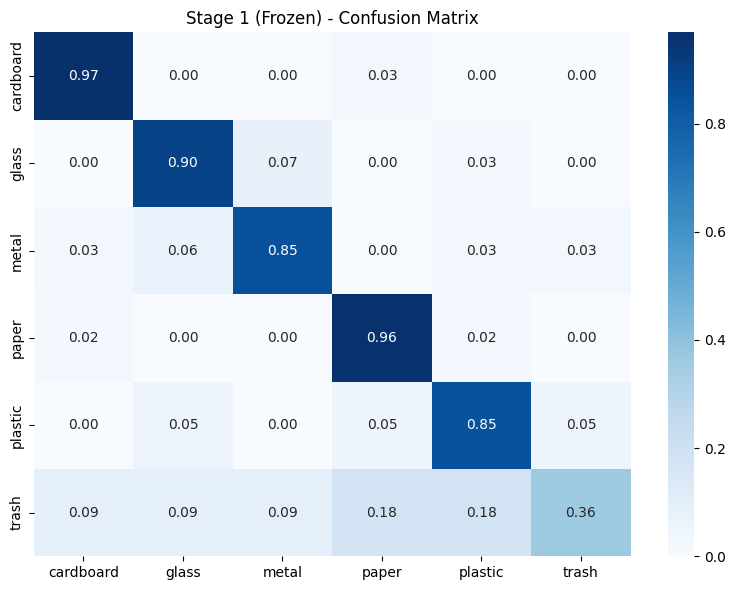


Stage 2 (Fine-Tuned) - Classification Report:
              precision    recall  f1-score   support

   cardboard       0.91      0.97      0.94        32
       glass       0.88      0.90      0.89        40
       metal       0.88      0.85      0.86        33
       paper       0.90      0.96      0.93        48
     plastic       0.87      0.85      0.86        39
       trash       0.57      0.36      0.44        11

    accuracy                           0.88       203
   macro avg       0.83      0.81      0.82       203
weighted avg       0.87      0.88      0.87       203



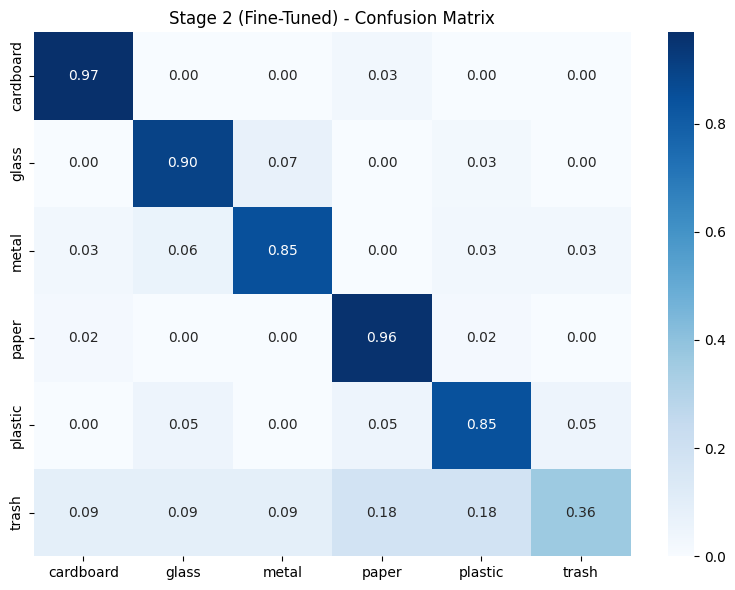

In [ ]:
print("="*60)
print("STAGE 1 vs STAGE 2 COMPARISON")
print("="*60)

def evaluate_model(model, dataset, name):
    y_true, y_pred = [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(preds, axis=1))

    print(f"\n{name} - Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    macro_f1 = f1_score(y_true, y_pred, average='macro')
    accuracy = accuracy_score(y_true, y_pred)

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'{name} - Confusion Matrix')
    plt.tight_layout()
    plt.show()

    return macro_f1, accuracy, y_true, y_pred

# Evaluate Stage 1
stage1_f1, stage1_acc, _, _ = evaluate_model(vit_model_stage1, val_ds, "Stage 1 (Frozen)")

# Evaluate Stage 2
stage2_f1, stage2_acc, _, _ = evaluate_model(model_stage2, val_ds, "Stage 2 (Fine-Tuned)")

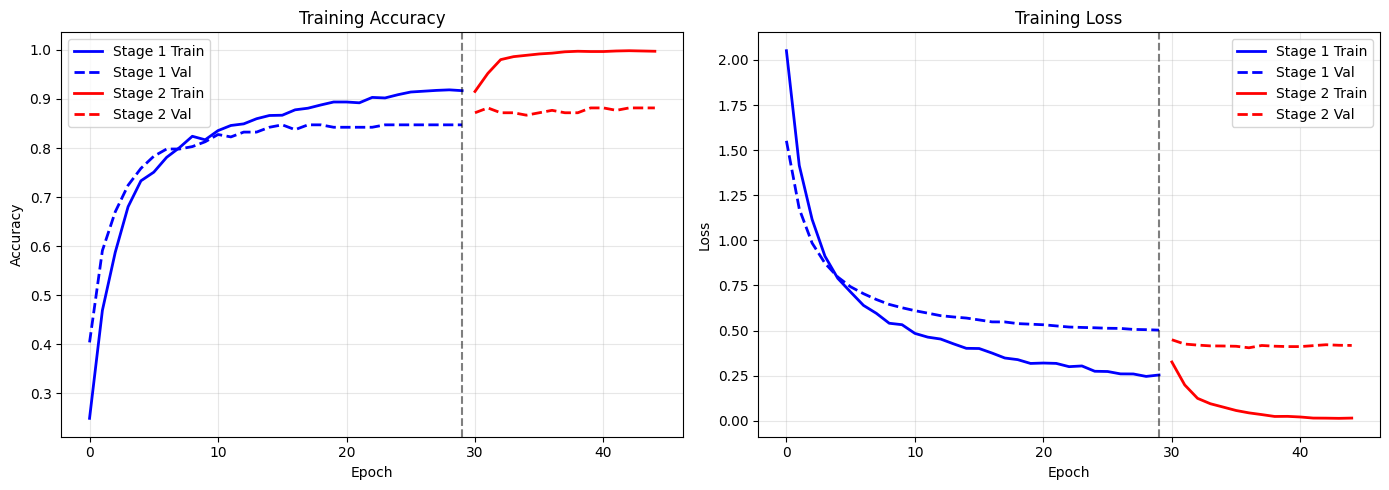

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history_stage1.history['accuracy'], 'b-', label='Stage 1 Train', linewidth=2)
axes[0].plot(history_stage1.history['val_accuracy'], 'b--', label='Stage 1 Val', linewidth=2)
axes[0].plot(range(len(history_stage1.history['accuracy']),
                  len(history_stage1.history['accuracy']) + len(history_stage2.history['accuracy'])),
              history_stage2.history['accuracy'], 'r-', label='Stage 2 Train', linewidth=2)
axes[0].plot(range(len(history_stage1.history['accuracy']),
                  len(history_stage1.history['accuracy']) + len(history_stage2.history['accuracy'])),
              history_stage2.history['val_accuracy'], 'r--', label='Stage 2 Val', linewidth=2)
axes[0].axvline(x=len(history_stage1.history['accuracy'])-1, color='black', linestyle='--', alpha=0.5)
axes[0].set_title('Training Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history_stage1.history['loss'], 'b-', label='Stage 1 Train', linewidth=2)
axes[1].plot(history_stage1.history['val_loss'], 'b--', label='Stage 1 Val', linewidth=2)
axes[1].plot(range(len(history_stage1.history['loss']),
                  len(history_stage1.history['loss']) + len(history_stage2.history['loss'])),
              history_stage2.history['loss'], 'r-', label='Stage 2 Train', linewidth=2)
axes[1].plot(range(len(history_stage1.history['loss']),
                  len(history_stage1.history['loss']) + len(history_stage2.history['loss'])),
              history_stage2.history['val_loss'], 'r--', label='Stage 2 Val', linewidth=2)
axes[1].axvline(x=len(history_stage1.history['loss'])-1, color='black', linestyle='--', alpha=0.5)
axes[1].set_title('Training Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('two_stage_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import pickle

# These should still be in memory from your Phase 1/Phase 2 cells
# If not, you'll need to re-split the data
try:
    print("Checking if test variables exist...")
    print(f"test_paths: {len(test_paths)} images")
    print(f"test_labels: {len(test_labels)} labels")

    # Save test set
    with open('test_set_isolated.pkl', 'wb') as f:
        pickle.dump({
            'paths': test_paths,
            'labels': test_labels,
            'class_names': class_names
        }, f)
    print("\n test_set_isolated.pkl recreated!")

except NameError as e:
    print(f" Error: {e}")
    print("test_paths or test_labels not defined.")
    print("You need to reload the dataset and create the split again.")

Checking if test variables exist...
test_paths: 506 images
test_labels: 506 labels

 test_set_isolated.pkl recreated!


In [ ]:
print("="*60)
print("FINAL TEST EVALUATION - BEST MODEL (50% Unfreeze)")
print("="*60)

# Load test set
with open('test_set_isolated.pkl', 'rb') as f:
    test_data = pickle.load(f)

test_paths = test_data['paths']
test_labels = test_data['labels']

# Create test dataset
test_ds = create_dataset(test_paths, test_labels, BATCH_SIZE, augment=False)

# Evaluate best model (model_stage2 from 50% unfreeze)
y_true_test, y_pred_test = [], []
for images, labels in test_ds:
    preds = model_stage2.predict(images, verbose=0)
    y_true_test.extend(labels.numpy())
    y_pred_test.extend(np.argmax(preds, axis=1))

print("\nFINAL TEST SET RESULTS:")
print(classification_report(y_true_test, y_pred_test, target_names=class_names))

# Calculate final metrics
test_f1 = f1_score(y_true_test, y_pred_test, average='macro')
test_acc = accuracy_score(y_true_test, y_pred_test)

print(f"\n FINAL RESULTS:")
print(f"   Macro F1: {test_f1:.4f}")
print(f"   Accuracy: {test_acc:.4f}")

FINAL TEST EVALUATION - BEST MODEL (50% Unfreeze)

FINAL TEST SET RESULTS:
              precision    recall  f1-score   support

   cardboard       0.99      0.95      0.97        81
       glass       0.96      0.97      0.97       100
       metal       0.93      0.90      0.91        82
       paper       0.93      0.92      0.93       119
     plastic       0.91      0.85      0.88        97
       trash       0.59      0.85      0.70        27

    accuracy                           0.92       506
   macro avg       0.88      0.91      0.89       506
weighted avg       0.92      0.92      0.92       506


 FINAL RESULTS:
   Macro F1: 0.8916
   Accuracy: 0.9150
